# Online Retail II: exploratory analysis

This notebook complements the SQL in `sql/` and the Metabase dashboard. It reads the cleaned star schema in `data/retail.db`
(built by `scripts/build_warehouse.py`). It covers data quality, seasonality, customer concentration, purchase timing and
cohort retention, and checks two of the dashboard's claims with significance tests.

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook")
ROOT = Path.cwd().parent
DOCS = ROOT / "docs"
con = sqlite3.connect(ROOT / "data" / "retail.db")
q = lambda sql: pd.read_sql_query(sql, con)

## 1. Data quality: what the ETL removed or flagged

In [2]:
q("SELECT * FROM etl_log")

,step,row_count
0,raw rows,1067371
1,dropped: exact duplicate lines,34335
2,dropped: non-cancel lines with qty<=0 or price<=0,6019
3,dropped: negative price lines,0
4,"flagged: non-product lines (postage, fees, adj...",5763
5,"kept, customer id missing (guest checkout)",229202
6,clean rows loaded,1027017


In [3]:
sales = q('''
SELECT f.invoice_no, f.invoice_ts, f.customer_key, f.country, f.quantity, f.revenue, d.year_month
FROM fact_sales f JOIN dim_date d USING (date_key)
WHERE f.is_cancellation = 0 AND f.is_non_product = 0
''')
sales["invoice_ts"] = pd.to_datetime(sales.invoice_ts)
print(f"{len(sales):,} sale lines | {sales.invoice_no.nunique():,} orders | "
      f"{sales.customer_key.nunique():,} identified customers")
print(f"Guest (no customer id) share of revenue: {sales.loc[sales.customer_key.isna(), 'revenue'].sum() / sales.revenue.sum():.1%}")

1,003,340 sale lines | 39,516 orders | 5,852 identified customers
Guest (no customer id) share of revenue: 13.1%


## 2. Seasonality: revenue peaks every November, so compare year over year rather than month over month

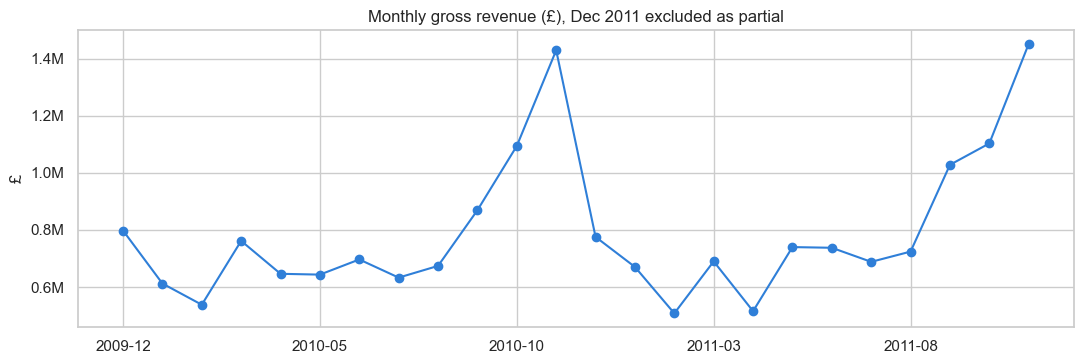

In [4]:
monthly = sales.groupby("year_month").revenue.sum().drop("2011-12")
fig, ax = plt.subplots(figsize=(11, 3.8))
monthly.plot(ax=ax, marker="o", color="#2F7FD8")
ax.set(title="Monthly gross revenue (£), Dec 2011 excluded as partial", xlabel="", ylabel="£")
ax.yaxis.set_major_formatter(lambda v, _: f"{v/1e6:.1f}M")
plt.tight_layout(); fig.savefig(DOCS / "monthly_revenue.png", dpi=150); plt.show()

## 3. Customer concentration: how dependent is revenue on the top accounts?

Top 1% of customers -> 31.9% of identified revenue
Top 10% of customers -> 63.9% of identified revenue
Top 20% of customers -> 77.2% of identified revenue


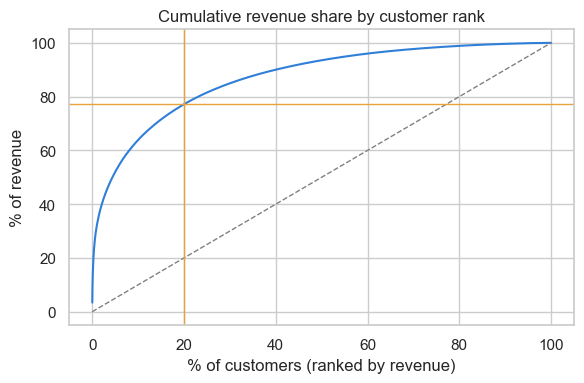

In [5]:
by_cust = sales.dropna(subset=["customer_key"]).groupby("customer_key").revenue.sum().sort_values(ascending=False)
cum = by_cust.cumsum() / by_cust.sum()
top = {p: cum.iloc[int(len(cum) * p) - 1] for p in (0.01, 0.10, 0.20)}
for p, share in top.items():
    print(f"Top {p:.0%} of customers -> {share:.1%} of identified revenue")

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(np.arange(1, len(cum) + 1) / len(cum) * 100, cum.values * 100, color="#2F7FD8")
ax.plot([0, 100], [0, 100], ls="--", color="grey", lw=1)
ax.axvline(20, color="#E8A33D", lw=1); ax.axhline(top[0.20] * 100, color="#E8A33D", lw=1)
ax.set(title="Cumulative revenue share by customer rank", xlabel="% of customers (ranked by revenue)",
       ylabel="% of revenue")
plt.tight_layout(); fig.savefig(DOCS / "concentration.png", dpi=150); plt.show()

## 4. When do orders happen? (UK local time)

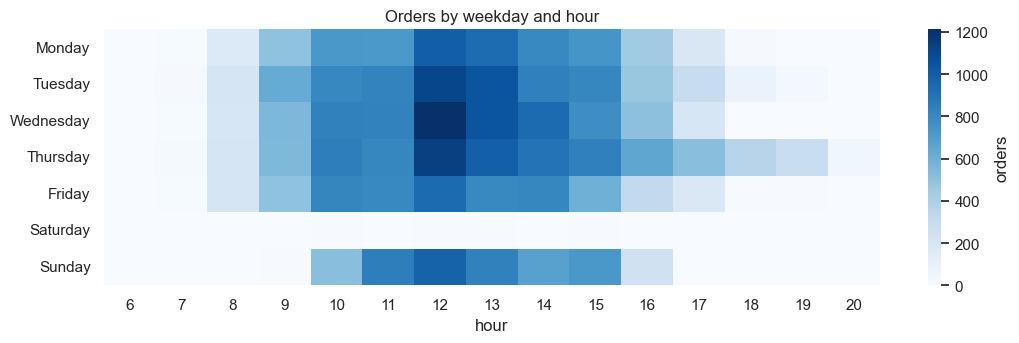

Saturday orders: 30


In [6]:
orders = sales.groupby("invoice_no").agg(ts=("invoice_ts", "min"), value=("revenue", "sum"),
                                         customer=("customer_key", "first"))
orders["weekday"] = pd.Categorical(orders.ts.dt.day_name(),
                                   ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
orders["hour"] = orders.ts.dt.hour
grid = orders.pivot_table(index="weekday", columns="hour", values="value", aggfunc="size", observed=False).fillna(0)
fig, ax = plt.subplots(figsize=(11, 3.6))
sns.heatmap(grid, cmap="Blues", ax=ax, cbar_kws={"label": "orders"})
ax.set(title="Orders by weekday and hour", xlabel="hour", ylabel="")
plt.tight_layout(); fig.savefig(DOCS / "order_timing.png", dpi=150); plt.show()
print("Saturday orders:", int(grid.loc["Saturday"].sum()))

Almost no Saturday trading and a 10:00–15:00 peak suggest a wholesale (B2B) customer base. That shapes the
recommendations: retention plays should target buyers' reorder cycles, not consumer impulse.

## 5. Cohort retention heatmap

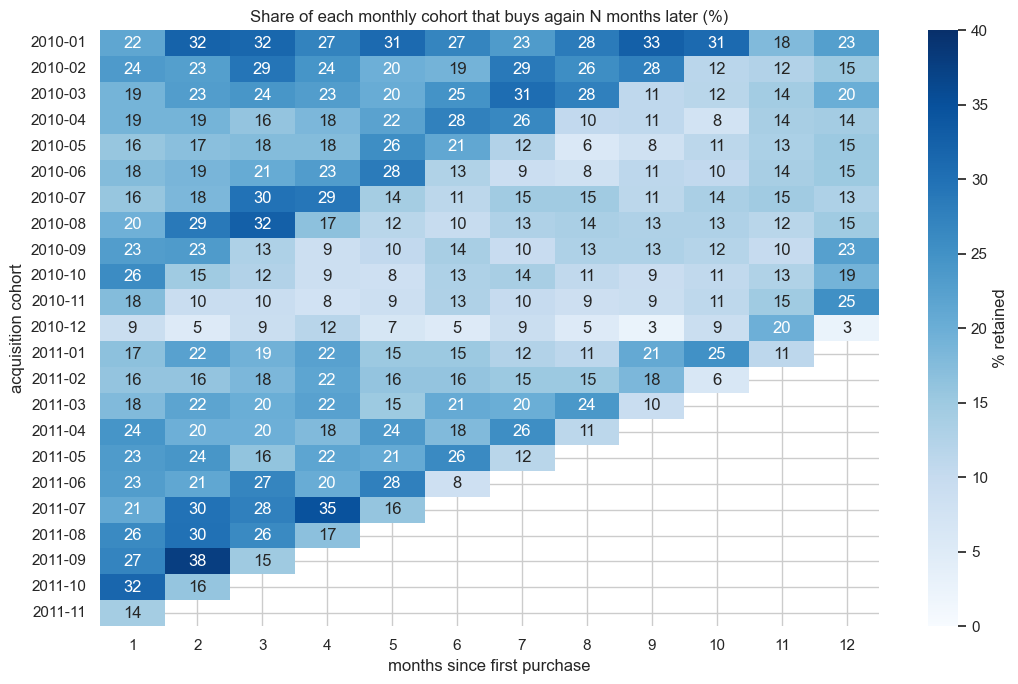

In [7]:
coh = pd.read_csv(ROOT / "outputs" / "02_cohort_retention.csv")
coh = coh[(coh.cohort_month >= "2010-01") & (coh.cohort_month <= "2011-11") & (coh.month_number.between(1, 12))]
mat = coh.pivot(index="cohort_month", columns="month_number", values="retention_pct")
fig, ax = plt.subplots(figsize=(11, 7))
sns.heatmap(mat, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=40, ax=ax, cbar_kws={"label": "% retained"})
ax.set(title="Share of each monthly cohort that buys again N months later (%)", xlabel="months since first purchase",
       ylabel="acquisition cohort")
plt.tight_layout(); fig.savefig(DOCS / "cohort_heatmap.png", dpi=150); plt.show()

## 6. Test 1: do new customers really churn more than returning ones? (2011 Q1–Q3)

In [8]:
churn = pd.read_csv(ROOT / "outputs" / "05_quarterly_churn.csv")
c = churn[churn.quarter.str.startswith("2011")].groupby("customer_type")[["active_customers", "churned_next_quarter"]].sum()
c["retained"] = c.active_customers - c.churned_next_quarter
c["churn_rate"] = c.churned_next_quarter / c.active_customers
chi2, p, *_ = stats.chi2_contingency(c[["churned_next_quarter", "retained"]].values)
print(c)
print(f"chi-square = {chi2:.1f}, p = {p:.2e}")

               active_customers  churned_next_quarter  retained  churn_rate
customer_type                                                              
new                        1097                   606       491    0.552416
returning                  4820                  1709      3111    0.354564
chi-square = 146.0, p = 1.27e-33


## 7. Test 2: is the H2 2011 rise in average order value real or noise?

In [9]:
ident = orders.dropna(subset=["customer"])
h2_10 = ident[(ident.ts >= "2010-07-01") & (ident.ts < "2010-12-01")].value
h2_11 = ident[(ident.ts >= "2011-07-01") & (ident.ts < "2011-12-01")].value
u, p = stats.mannwhitneyu(h2_11, h2_10, alternative="greater")
print(f"Median order value Jul–Nov 2010: £{h2_10.median():.0f} (n={len(h2_10):,})")
print(f"Median order value Jul–Nov 2011: £{h2_11.median():.0f} (n={len(h2_11):,})")
print(f"Mann-Whitney U (2011 > 2010): p = {p:.2e}")

Median order value Jul–Nov 2010: £304 (n=8,975)
Median order value Jul–Nov 2011: £306 (n=8,872)
Mann-Whitney U (2011 > 2010): p = 8.04e-02


Order values are heavily right-skewed (a few wholesale orders above £10k), so the rank-based Mann-Whitney test is
used instead of a t-test.